# `rioxarray`

In this lesson we will introduce [`rioxarray`](https://corteva.github.io/rioxarray/stable/), a Python extension for `xarray` to manipulate `xarray.DataArray`s as rasters. 

The name `rioxarray` stands for *raster input/output + xarray*. 

## About the data
The raster files we will use today come from the [US National Agriculture Imagery Program (NAIP)](https://naip-usdaonline.hub.arcgis.com). 
NAIP images are are high-resolution aerial images with four spectral bands: red (R), green (G), blue (B) and near-infrared (NIR). 
The raster's we'll use today are from 2020.

The data used in this lesson was pre-processing from a complete NAIP scene to separate the RGB bands from the NIR band and reduce the spatial extent. 
The data was accessed through [Microsoft's Planetary Computer NAIP data repository](https://planetarycomputer.microsoft.com/dataset/naip#overview).

## Import a TIF file

Let's start by loading the libraries we will use: 

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import geopandas as gpd

import rioxarray as rioxr

There are [multiple ways of opening a TIF file using `xarray` or `rioxarray`](https://corteva.github.io/rioxarray/html/getting_started/getting_started.html). 
Using the `rioxarray.open_rasterio()` function to open the TIF file is a simple way to import the raster file as an `xarray.DataArray` and make sure all our geospatial data gets loaded correctly:

In [2]:
# Import NIR TIF file
fp = os.path.join('data',
                  'rioxarray_lesson_data',
                  'NAIP_SB_nir.tif')
nir = rioxr.open_rasterio(fp)
nir



<xarray.DataArray (band: 1, y: 3208, x: 2419)> Size: 8MB
[7760152 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [3]:
# Access attributes directly
print('Shape: ', nir.shape)
print('Data type: ', nir.dtype)

Shape:  (1, 3208, 2419)
Data type:  uint8


In [4]:
nir.plot()

## Drop a dimension

The raster has an unnecessary extra dimension: band.

Sizes of dimensions: {'band': 1, 'y': 3208, 'x': 2419}


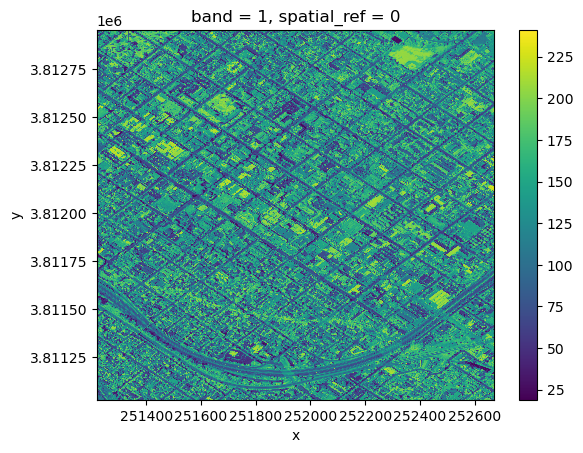

In [5]:
print('Sizes of dimensions:', dict(nir.sizes))

- `band` has length 1, so it makes the `xarray` 3-d for no reason
- `squeeze` removes a dimension of length 1
- `drop=True` removes the coordinates for that dimension

In [6]:
# Original dimensions and coordinates 
print(nir.dims, nir.coords, '\n')

# Remove length 1 dimension (band) and its coordinates
nir = nir.squeeze('band', drop=True)

('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 



## `rio` accessor

In [7]:
# Examine raster attributes using rio accessor
print('Number of bands: ', nir.rio.count)
print('Height: ', nir.rio.height)
print('Width: ', nir.rio.width, '\n')

print('CRS: ', nir.rio.crs, '\n')

print('Spatial bounding box: ')
print(nir.rio.bounds())



Number of bands:  1
Height:  3208
Width:  2419 

CRS:  EPSG:26911 

Spatial bounding box: 
(251218.8, 3811027.2, 252670.19999999998, 3812952.0)


In [8]:
# Import rgd TIF file
fp = os.path.join('data',
                  'rioxarray_lesson_data',
                  'NAIP_SB_rgb.tif')
rgb = rioxr.open_rasterio(fp)
rgb

<xarray.DataArray (band: 3, y: 3208, x: 2419)> Size: 23MB
[23280456 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Check-in: obtain shape, number of bands, data type and CRS

In [9]:
# Examine raster attributes
print('Shape: ', rgb.shape)
print('Data type: ', rgb.dtype)
print('Sizes of dimensions:', dict(rgb.sizes))
print('Number of bands: ', rgb.rio.count)
print('Height: ', rgb.rio.height)
print('Width: ', rgb.rio.width, '\n')

print('CRS: ', rgb.rio.crs, '\n')

print('Spatial bounding box: ')
print(rgb.rio.bounds())

Shape:  (3, 3208, 2419)
Data type:  uint8
Sizes of dimensions: {'band': 3, 'y': 3208, 'x': 2419}
Number of bands:  3
Height:  3208
Width:  2419 

CRS:  EPSG:26911 

Spatial bounding box: 
(251218.8, 3811027.2, 252670.19999999998, 3812952.0)


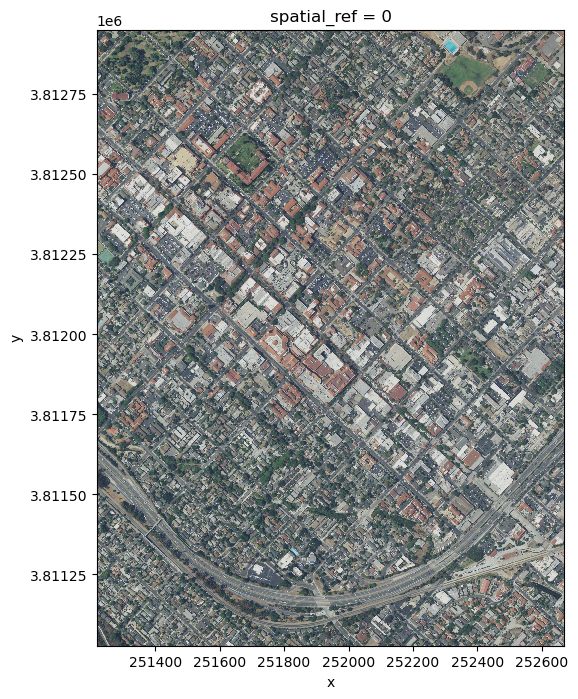

In [10]:
# Plot three bands as rgb image
rgb_aspect_ratio = rgb.rio.width / rgb.rio.height # Raster's aspect ratio
rgb.plot.imshow(figsize=(8*rgb_aspect_ratio,8))

In [11]:
# Import aoi  file
fp = os.path.join('data',
                  'rioxarray_lesson_data',
                  'SB_aoi.geojson')
aoi = gpd.read_file(fp)
aoi

,geometry
0,"POLYGON ((-119.70609 34.42642, -119.70609 34.4..."


<Axes: >

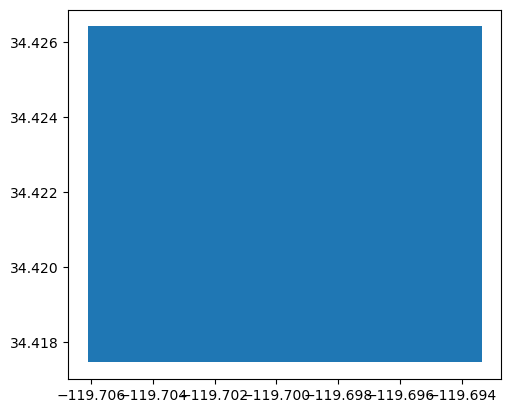

In [12]:
aoi.plot()

In [13]:
# Examine CRS

print('aoi CRS: ', aoi.crs)
print('nir CRS: ', nir.rio.crs)
print('rgb CRS: ', rgb.rio.crs)

aoi CRS:  EPSG:4326
nir CRS:  EPSG:26911
rgb CRS:  EPSG:26911


In [14]:
# Reproject our aoi to rgb crs
aoi = aoi.to_crs(rgb.rio.crs)
assert aoi.crs == rgb.rio.crs

In [15]:
aoi.crs

<Projected CRS: EPSG:26911>
Name: NAD83 / UTM zone 11N
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: UTM zone 11N
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

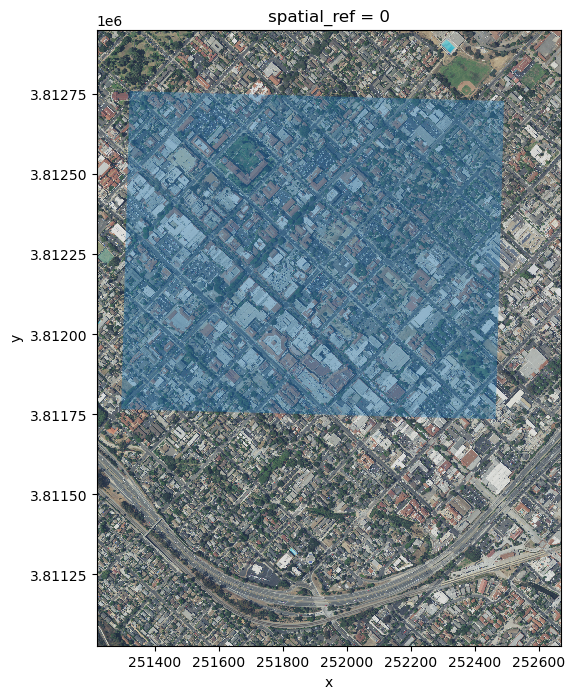

In [16]:
# Plot rgb raster with the AOI overlay
fig, ax = plt.subplots(figsize=(8*rgb_aspect_ratio, 8))
rgb.plot.imshow(ax=ax)
aoi.plot(ax=ax, alpha = 0.4)
plt.show()

In [17]:
aoi.total_bounds

array([ 251294.69376981, 3811735.1717313 ,  252491.02511929,
       3812760.31191696])

In [18]:
# Clip to bounding box of aoi polygon 

rgb_small = rgb.rio.clip_box(*aoi.total_bounds)

In [19]:
nir_small = nir.rio.clip_box(*aoi.total_bounds)

Original shape: (3208, 2419)
Clipped shape: (1710, 1995)


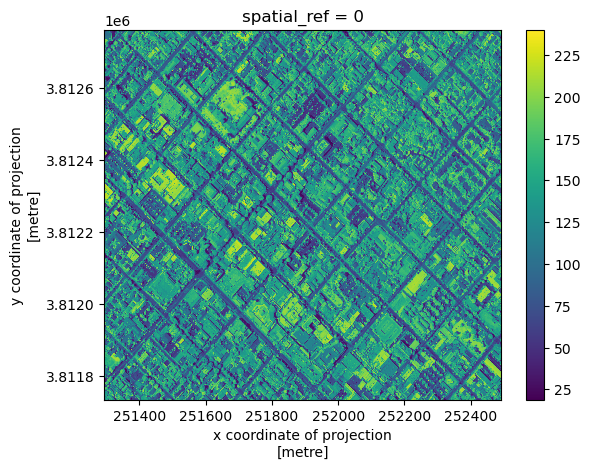

In [20]:
# Examine clipped data
print('Original shape:', nir.shape)
print('Clipped shape:', nir_small.shape)

nir_small.plot()

## Raster math

We will compute the normalized difference vegetation index (NDVI) over our AOI.

NDVI hecks whether an area has live green vegetation. 

NDVI is always between -1 and 1: valyes of about 0.6 correspond to lush vegetation. Water, roofs, pavement are all close to zero or negative. Sand, rock, snow, 0.1 and below. Generally above ~0.1 is vegetation.

NDVI uses NIR and red bands: 

$$NDVI = \frac{NIR - Red}{NIR + Red}$$

In [21]:
# Select dimension by name and coordinate by label
red_small = rgb_small.sel(band=1)
red_small

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

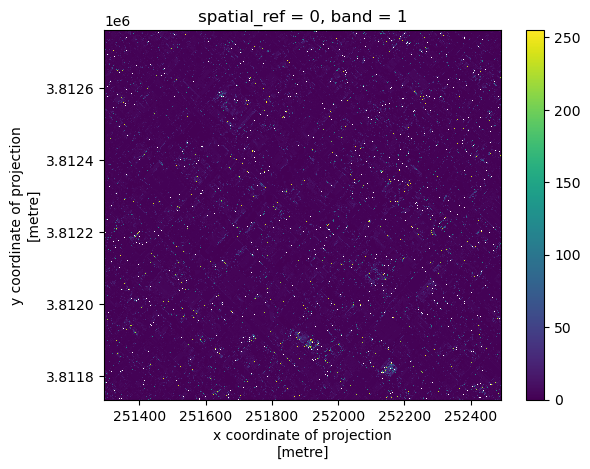

In [22]:
ndvi = (nir_small - red_small)/(nir_small + red_small)
ndvi.plot()

In [23]:
print('Minimum NDVI:', ndvi.min().values)
print('Maximum NDVI:', ndvi.max().values)

Minimum NDVI: 0.0
Maximum NDVI: inf
